Feature Selection is the process of selecting only the most important features (columns) from a dataset while removing irrelevant, redundant, or less useful features before training a machine learning model.

Problem without feature selection

50 Features -> Model -> Slow Training -> Overfitting -> Lower Accuracy

After Feature Selection

50 Features-> 10 Important Features-> Fast Training -> Better Accuracy -> Easy Interpretation



Benefits

Faster model training

Better accuracy

Less overfitting

Easier interpretation

Less memory usage

Removes irrelevant columns

Types of feature selection:
1. Filter Method
2. Wrapper Method
3. Embedded Method

Variance Thresholding

Variance Threshold removes features with very low variance, as they contribute little useful information to the learning process. Features with almost constant values are typically discarded.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Teen_Mental_Health_Dataset.csv")

df.head()

,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,14,male,7.9,Instagram,7.4,2.9,3.01,1.5,low,2,2,1,0
1,19,female,1.9,TikTok,8.0,2.9,3.22,0.8,high,8,1,10,0
2,17,female,1.3,Instagram,7.6,0.5,3.92,0.0,high,2,4,2,0
3,15,male,7.4,TikTok,6.9,1.6,3.48,0.8,medium,1,7,9,0
4,15,female,4.7,Both,4.9,3.0,2.37,1.4,medium,3,5,2,0


In [ ]:
X = df.drop("depression_label", axis=1)
y = df["depression_label"]

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

categorical_columns = [
    "gender",
    "platform_usage",
    "social_interaction_level"
]

for col in categorical_columns:
    X[col] = le.fit_transform(X[col])

print(X.head())

   age  gender  daily_social_media_hours  platform_usage  sleep_hours  \
0   14       1                       7.9               1          7.4   
1   19       0                       1.9               2          8.0   
2   17       0                       1.3               1          7.6   
3   15       1                       7.4               2          6.9   
4   15       0                       4.7               0          4.9   

   screen_time_before_sleep  academic_performance  physical_activity  \
0                       2.9                  3.01                1.5   
1                       2.9                  3.22                0.8   
2                       0.5                  3.92                0.0   
3                       1.6                  3.48                0.8   
4                       3.0                  2.37                1.4   

   social_interaction_level  stress_level  anxiety_level  addiction_level  
0                         1             2           

In [ ]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)

X_var = selector.fit_transform(X)

selected_features = X.columns[selector.get_support()]

print("Selected Features after Variance Threshold:\n")
print(selected_features)

Selected Features after Variance Threshold:

Index(['age', 'gender', 'daily_social_media_hours', 'platform_usage',
       'sleep_hours', 'screen_time_before_sleep', 'academic_performance',
       'physical_activity', 'social_interaction_level', 'stress_level',
       'anxiety_level', 'addiction_level'],
      dtype='object')


In [ ]:
variance = X.var()

variance_df = pd.DataFrame({
    "Feature": variance.index,
    "Variance": variance.values
})

variance_df = variance_df.sort_values(by="Variance", ascending=False)

print(variance_df)

                     Feature  Variance
9               stress_level  8.429090
10             anxiety_level  8.176469
11           addiction_level  8.012452
2   daily_social_media_hours  4.119272
0                        age  4.088271
4                sleep_hours  2.081317
3             platform_usage  0.658014
8   social_interaction_level  0.653177
5   screen_time_before_sleep  0.513601
7          physical_activity  0.338939
6       academic_performance  0.332649
1                     gender  0.250052


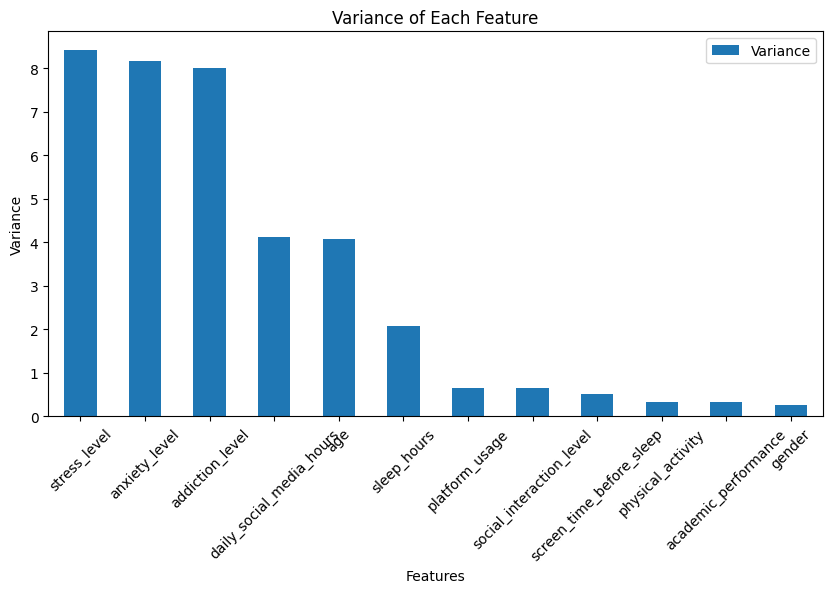

In [ ]:
import matplotlib.pyplot as plt

variance_df.plot(
    x="Feature",
    y="Variance",
    kind="bar",
    figsize=(10,5)
)

plt.title("Variance of Each Feature")
plt.xlabel("Features")
plt.ylabel("Variance")

plt.xticks(rotation=45)

plt.show()

In [ ]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.5)

X_new = selector.fit_transform(X)

selected_features = X.columns[selector.get_support()]

removed_features = X.columns[~selector.get_support()]

In [ ]:
print("Original Features")
print("-----------------")
print(list(X.columns))

print()

print("Selected Features")
print("-----------------")
print(list(selected_features))

print()

print("Removed Features")
print("----------------")
print(list(removed_features))

Original Features
-----------------
['age', 'gender', 'daily_social_media_hours', 'platform_usage', 'sleep_hours', 'screen_time_before_sleep', 'academic_performance', 'physical_activity', 'social_interaction_level', 'stress_level', 'anxiety_level', 'addiction_level']

Selected Features
-----------------
['age', 'daily_social_media_hours', 'platform_usage', 'sleep_hours', 'screen_time_before_sleep', 'social_interaction_level', 'stress_level', 'anxiety_level', 'addiction_level']

Removed Features
----------------
['gender', 'academic_performance', 'physical_activity']


In [ ]:
variance_values = X.var()

result = pd.DataFrame({
    "Feature": X.columns,
    "Variance": variance_values,
    "Selected": selector.get_support()
})

print(result)

                                           Feature  Variance  Selected
age                                            age  4.088271      True
gender                                      gender  0.250052     False
daily_social_media_hours  daily_social_media_hours  4.119272      True
platform_usage                      platform_usage  0.658014      True
sleep_hours                            sleep_hours  2.081317      True
screen_time_before_sleep  screen_time_before_sleep  0.513601      True
academic_performance          academic_performance  0.332649     False
physical_activity                physical_activity  0.338939     False
social_interaction_level  social_interaction_level  0.653177      True
stress_level                          stress_level  8.429090      True
anxiety_level                        anxiety_level  8.176469      True
addiction_level                    addiction_level  8.012452      True


Correlation Coefficient

The Correlation Coefficient measures the strength and direction of the relationship between a feature and the target variable. Features with higher absolute correlation values are generally considered more relevant.

In [ ]:
corr = df.corr(numeric_only=True)

target_corr = corr["depression_label"].drop("depression_label")

print(target_corr.sort_values(ascending=False))

daily_social_media_hours    0.175201
stress_level                0.170474
anxiety_level               0.169566
age                         0.010973
academic_performance        0.001441
addiction_level            -0.013952
screen_time_before_sleep   -0.016502
physical_activity          -0.017598
sleep_hours                -0.190630
Name: depression_label, dtype: float64


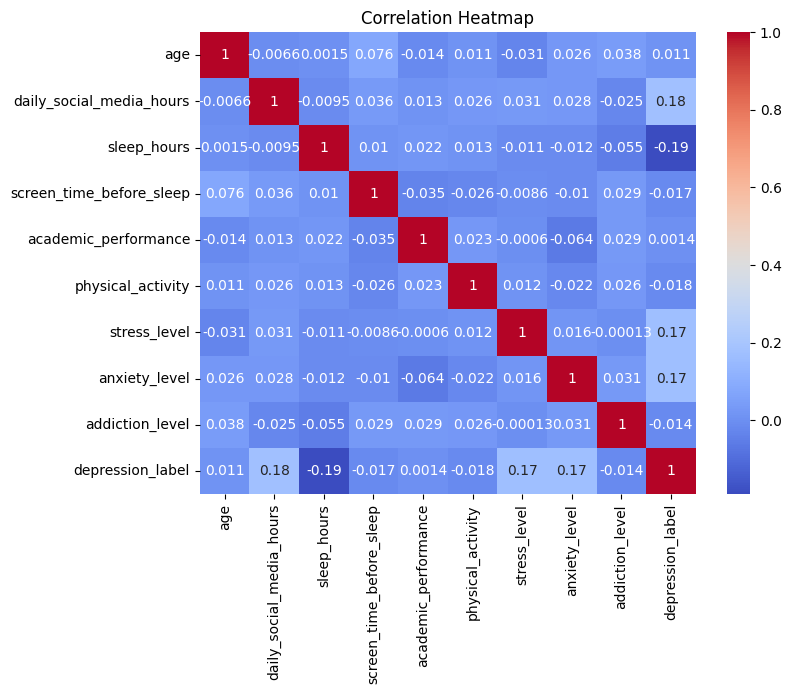

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

Chi Squared Test

The Chi-Square test evaluates the dependency between categorical features and the target variable. Features with higher Chi-Square scores are considered more important.

Higher values indicate a stronger relationship between the feature and the target variable.
Commonly used for classification tasks involving categorical data.

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2

scaler = MinMaxScaler()

X_scaled = scaler.fit_transform(X)

chi_selector = SelectKBest(score_func=chi2, k="all")

chi_selector.fit(X_scaled, y)

chi_scores = pd.DataFrame({
    "Feature": X.columns,
    "Chi2 Score": chi_selector.scores_
})

chi_scores = chi_scores.sort_values(
    by="Chi2 Score",
    ascending=False
)

print(chi_scores)

                     Feature  Chi2 Score
4                sleep_hours    7.404669
9               stress_level    7.340388
10             anxiety_level    6.754838
2   daily_social_media_hours    6.123781
1                     gender    0.230189
3             platform_usage    0.130825
7          physical_activity    0.062025
5   screen_time_before_sleep    0.054078
11           addiction_level    0.045518
0                        age    0.033589
8   social_interaction_level    0.009839
6       academic_performance    0.000418


Mutual Information

Mutual Information measures how much information a feature provides about the target variable. It can capture both linear and non-linear relationships.

Higher values indicate that the feature contains more useful information about the target.
A value of 0 indicates independence between the feature and target.

In [ ]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    X,
    y,
    random_state=42
)

mi_scores = pd.DataFrame({
    "Feature": X.columns,
    "Mutual Information": mi
})

mi_scores = mi_scores.sort_values(
    by="Mutual Information",
    ascending=False
)

print(mi_scores)

                     Feature  Mutual Information
2   daily_social_media_hours            0.025425
9               stress_level            0.024998
10             anxiety_level            0.024137
4                sleep_hours            0.021366
11           addiction_level            0.007395
7          physical_activity            0.001217
0                        age            0.000000
1                     gender            0.000000
3             platform_usage            0.000000
5   screen_time_before_sleep            0.000000
6       academic_performance            0.000000
8   social_interaction_level            0.000000


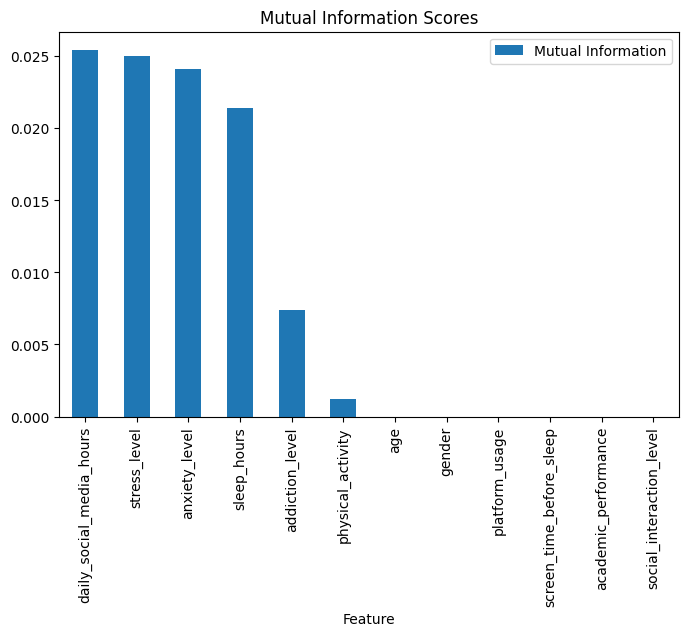

In [ ]:
mi_scores.plot.bar(
    x="Feature",
    y="Mutual Information",
    figsize=(8,5)
)

plt.title("Mutual Information Scores")

plt.show()

F-Test (ANOVA)

ANOVA (Analysis of Variance) measures whether the mean values of a feature differ significantly across target classes. Features with higher F-scores are generally more discriminative.

Higher F-scores indicate greater separation between classes.
Commonly used for classification problems with numerical features.

In [ ]:
from sklearn.feature_selection import f_classif

f_scores, p_values = f_classif(X, y)

anova = pd.DataFrame({
    "Feature": X.columns,
    "F Score": f_scores,
    "P Value": p_values
})

anova = anova.sort_values(
    by="F Score",
    ascending=False
)

print(anova)

                     Feature    F Score       P Value
4                sleep_hours  45.176611  2.778312e-11
2   daily_social_media_hours  37.937501  9.955180e-10
9               stress_level  35.857486  2.802297e-09
10             anxiety_level  35.465437  3.407107e-09
1                     gender   0.471582  4.923933e-01
3             platform_usage   0.399755  5.273365e-01
7          physical_activity   0.371110  5.425155e-01
5   screen_time_before_sleep   0.326309  5.679479e-01
11           addiction_level   0.233249  6.292134e-01
0                        age   0.144252  7.041569e-01
8   social_interaction_level   0.031281  8.596443e-01
6       academic_performance   0.002487  9.602373e-01


In [ ]:
from sklearn.preprocessing import LabelEncoder

X = df.drop("depression_label", axis=1)
y = df["depression_label"]

le = LabelEncoder()

categorical_columns = [
    "gender",
    "platform_usage",
    "social_interaction_level"
]

for col in categorical_columns:
    X[col] = le.fit_transform(X[col])
temp = X.copy()

temp["depression_label"] = y
corr = temp.corr()

target_corr = corr["depression_label"].drop("depression_label")

print(target_corr)
print(len(target_corr))

age                         0.010973
gender                     -0.019836
daily_social_media_hours    0.175201
platform_usage              0.018264
sleep_hours                -0.190630
screen_time_before_sleep   -0.016502
academic_performance        0.001441
physical_activity          -0.017598
social_interaction_level    0.005110
stress_level                0.170474
anxiety_level               0.169566
addiction_level            -0.013952
Name: depression_label, dtype: float64
12


In [ ]:
comparison = pd.DataFrame({
    "Feature": X.columns,
    "Correlation": target_corr.values,
    "Chi2": chi_selector.scores_,
    "Mutual_Info": mi,
    "F_Score": f_scores
})

comparison = comparison.sort_values(
    by="Mutual_Info",
    ascending=False
)

print(comparison)

                     Feature  Correlation      Chi2  Mutual_Info    F_Score
2   daily_social_media_hours     0.175201  6.123781     0.025425  37.937501
9               stress_level     0.170474  7.340388     0.024998  35.857486
10             anxiety_level     0.169566  6.754838     0.024137  35.465437
4                sleep_hours    -0.190630  7.404669     0.021366  45.176611
11           addiction_level    -0.013952  0.045518     0.007395   0.233249
7          physical_activity    -0.017598  0.062025     0.001217   0.371110
0                        age     0.010973  0.033589     0.000000   0.144252
1                     gender    -0.019836  0.230189     0.000000   0.471582
3             platform_usage     0.018264  0.130825     0.000000   0.399755
5   screen_time_before_sleep    -0.016502  0.054078     0.000000   0.326309
6       academic_performance     0.001441  0.000418     0.000000   0.002487
8   social_interaction_level     0.005110  0.009839     0.000000   0.031281


In [ ]:
comparison["Correlation_Rank"] = comparison["Correlation"].abs().rank(ascending=False)
comparison["Chi2_Rank"] = comparison["Chi2"].rank(ascending=False)
comparison["MI_Rank"] = comparison["Mutual_Info"].rank(ascending=False)
comparison["F_Rank"] = comparison["F_Score"].rank(ascending=False)

print(comparison)

                     Feature  Correlation      Chi2  Mutual_Info    F_Score  \
2   daily_social_media_hours     0.175201  6.123781     0.025425  37.937501   
9               stress_level     0.170474  7.340388     0.024998  35.857486   
10             anxiety_level     0.169566  6.754838     0.024137  35.465437   
4                sleep_hours    -0.190630  7.404669     0.021366  45.176611   
11           addiction_level    -0.013952  0.045518     0.007395   0.233249   
7          physical_activity    -0.017598  0.062025     0.001217   0.371110   
0                        age     0.010973  0.033589     0.000000   0.144252   
1                     gender    -0.019836  0.230189     0.000000   0.471582   
3             platform_usage     0.018264  0.130825     0.000000   0.399755   
5   screen_time_before_sleep    -0.016502  0.054078     0.000000   0.326309   
6       academic_performance     0.001441  0.000418     0.000000   0.002487   
8   social_interaction_level     0.005110  0.009839 